# Análisis de precios de alquiler en CABA

## Objetivo

Responder las preguntas del proyecto a partir del dataset limpio generado por `src/cleaning.py` (`python -m src.cleaning`).

## Decisiones metodológicas

- **Moneda común:** todos los precios están en USD. Los avisos en pesos se convirtieron con el dólar MEP del día del scraping.
- **Una fila por departamento:** el dataset conserva el historial de cada aviso. Para comparar barrios se usa solo la publicación más reciente de cada `id`, así cada departamento cuenta una vez.
- **Mediana, no promedio:** la distribución de precios es asimétrica, y unos pocos departamentos muy caros inflan el promedio.
- **Mínimo de 30 departamentos por barrio** para incluirlo en los rankings.

In [1]:
import sys
sys.path.append("..")

import pandas as pd

from src.analysis import resumen_por_barrio, ultima_publicacion
from src.charts import guardar, ranking_usd_m2_por_barrio

pd.set_option("display.float_format", "{:,.1f}".format)

In [2]:
df = pd.read_parquet("../data/processed/alquileres_limpio.parquet")
deptos = ultima_publicacion(df)

print(f"Publicaciones en el dataset limpio: {len(df):,}")
print(f"Departamentos únicos: {len(deptos):,}")

Publicaciones en el dataset limpio: 52,618
Departamentos únicos: 29,038


## 1. ¿Qué barrios tienen el precio más alto por m²?

Se calcula la mediana del alquiler mensual en USD por m² de cada barrio.

In [3]:
resumen = resumen_por_barrio(deptos)
mediana_caba = deptos["precio_usd_m2"].median()

print(f"Mediana CABA: USD {mediana_caba:.1f} por m²")
print(f"Barrios incluidos: {len(resumen)} de {deptos['barrio'].nunique()}")
resumen

Mediana CABA: USD 10.2 por m²
Barrios incluidos: 40 de 48


,propiedades,comuna,mediana_usd_m2,p25_usd_m2,p75_usd_m2,mediana_precio_usd,mediana_m2
barrio,,,,,,,
Puerto Madero,1409,1,22.7,18.1,28.1,"2,250.0",96.0
Palermo,6734,14,11.8,9.6,15.6,600.0,50.0
Núñez,997,13,11.2,9.4,14.0,551.6,50.0
Belgrano,2998,13,10.8,9.0,13.6,573.3,51.0
Retiro,637,1,10.7,8.3,13.5,622.6,60.0
Recoleta,4476,2,10.2,8.5,12.8,540.2,53.0
Colegiales,547,13,10.1,8.7,12.5,487.9,45.0
Chacarita,198,15,9.9,8.7,11.6,399.4,40.5
Saavedra,307,12,9.8,8.7,11.6,450.5,45.0


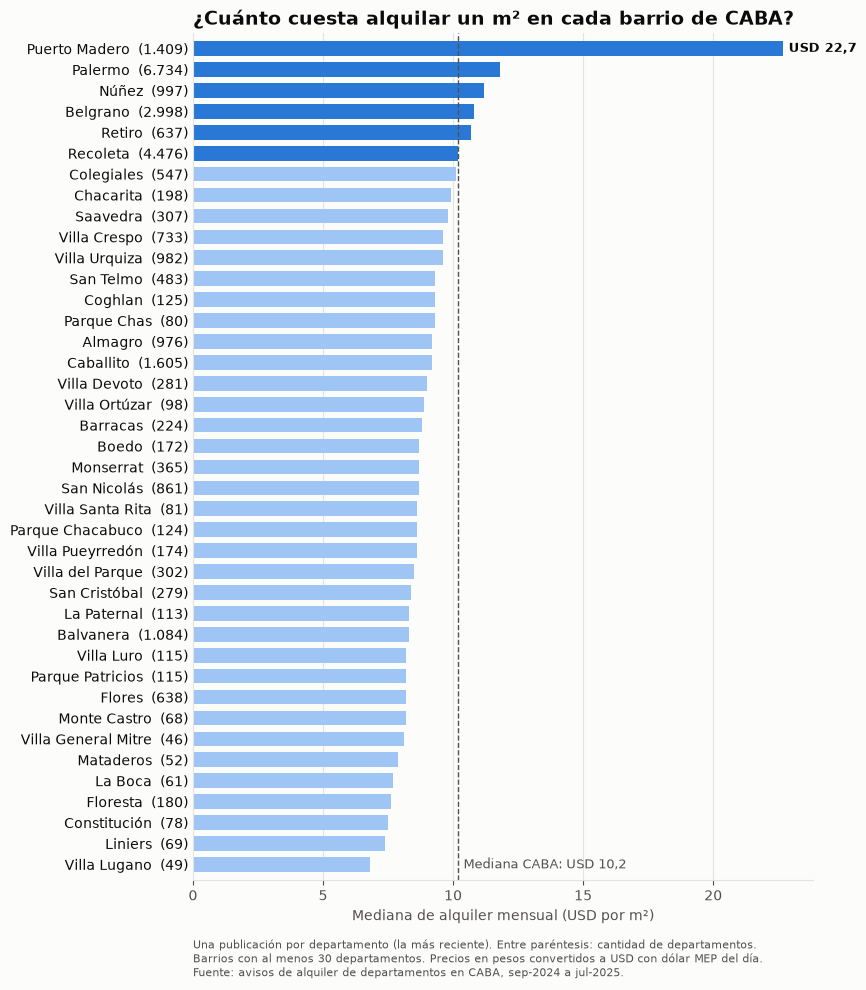

In [4]:
fig = ranking_usd_m2_por_barrio(resumen, mediana_caba)
guardar(fig, "01_usd_m2_por_barrio");

### Conclusiones

- **Puerto Madero es un mercado aparte:** USD 22,7 por m², más del doble de la mediana de CABA (USD 10,2) y casi el doble del segundo barrio, Palermo (USD 11,8). Además sus departamentos son más grandes (mediana de 96 m² contra unos 45 a 50 m² en el resto), así que el alquiler mensual típico llega a USD 2.250.
- **El corredor norte encabeza el ranking:** Palermo, Núñez, Belgrano, Retiro y Recoleta son los únicos barrios por encima de la mediana de la ciudad.
- **Los barrios del sur y del oeste son los más accesibles:** Villa Lugano (USD 6,8), Liniers, Constitución, Floresta y La Boca están entre USD 6,8 y 7,7 por m².
- **Fuera de los extremos, las diferencias son chicas:** más de 30 barrios están entre USD 7,5 y 10 por m². Por ejemplo, entre Chacarita (USD 9,9) y Flores (USD 8,2) hay USD 1,7 por m². En un departamento típico de 45 m², eso son unos USD 75 por mes.

**Limitaciones:** son precios publicados, no precios de cierre. Además, 8 barrios quedaron fuera por tener menos de 30 departamentos publicados: Agronomía, Nueva Pompeya, Parque Avellaneda, Versalles, Villa Real, Villa Riachuelo, Villa Soldati y Vélez Sársfield.